<a href="https://colab.research.google.com/github/dharshraj/deep-learn/blob/main/Unit_3_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

#### Experiments 33 to 45: Convolutional Neural Networks (CNNs), Batch Normalization, and Image Augmentation

In [ ]:
# Load standard CIFAR-10 dataset for experiments 33-45
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

169811968/170498071 ━━━━━━━━━━━━━━━━━━━━ 8s 12us/step

In [7]:
# Exp 42 & 43: Defect detection / Classification CNN model with evaluation metrics
model_cnn = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (5, 5), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model_cnn.fit(x_train[:5000], y_train[:5000], epochs=5, validation_data=(x_test[:1000], y_test[:1000]))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.2344 - loss: 2.0420 - val_accuracy: 0.3030 - val_loss: 1.8839
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - accuracy: 0.3890 - loss: 1.6551 - val_accuracy: 0.4150 - val_loss: 1.5981
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.4644 - loss: 1.4850 - val_accuracy: 0.4410 - val_loss: 1.5401
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.5126 - loss: 1.3770 - val_accuracy: 0.4870 - val_loss: 1.4760
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.5344 - loss: 1.3099 - val_accuracy: 0.5000 - val_loss: 1.3707


In [3]:
# Exp 44: Batch Normalization Comparison
def create_model(use_bn=False):
    model = models.Sequential()
    model.add(layers.Conv2D(32, (3, 3), input_shape=(32, 32, 3)))
    if use_bn:
        model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(10, activation='softmax'))
    return model

model_no_bn = create_model(use_bn=False)
model_no_bn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_no_bn = model_no_bn.fit(x_train[:2000], y_train[:2000], epochs=3, verbose=0)

model_bn = create_model(use_bn=True)
model_bn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_bn = model_bn.fit(x_train[:2000], y_train[:2000], epochs=3, verbose=0)

print("Without BN final accuracy:", history_no_bn.history['accuracy'][-1])
print("With BN final accuracy:", history_bn.history['accuracy'][-1])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Without BN final accuracy: 0.4584999978542328
With BN final accuracy: 0.5745000243186951


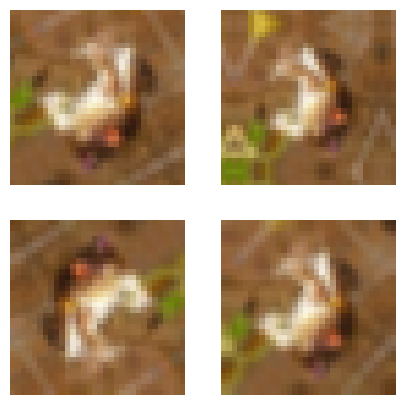

In [4]:
# Exp 45: Image Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

# Visualize augmented sample
plt.figure(figsize=(5, 5))
for i in range(4):
    augmented_image = data_augmentation(tf.expand_dims(x_train[0], 0))
    plt.subplot(2, 2, i + 1)
    plt.imshow(augmented_image[0])
    plt.axis("off")
plt.show()

#### Experiment 46: Transfer Learning with Pretrained Models

In [5]:
base_model = tf.keras.applications.ResNet50(input_shape=(32, 32, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze pretrained layers

model_transfer = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(10, activation='softmax')
])

model_transfer.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_transfer.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 1, 1, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,608,202 (90.06 MB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

#### Experiments 47 & 48: Recurrent Neural Networks (RNN)

In [6]:
# Exp 47 & 48: Create sequence dataset for temperature prediction / sensor dependencies
seq_len = 10
num_samples = 1000

# Generate synthetic sequential data (sine wave with noise)
time = np.linspace(0, 100, num_samples)
series = np.sin(time) + np.random.normal(0, 0.1, num_samples)

X, y = [], []
for i in range(len(series) - seq_len):
    X.append(series[i:i+seq_len])
    y.append(series[i+seq_len])

X = np.array(X).reshape(-1, seq_len, 1)
y = np.array(y)

# Implement Simple RNN
model_rnn = models.Sequential([
    layers.SimpleRNN(32, input_shape=(seq_len, 1)),
    layers.Dense(1)
])

model_rnn.compile(optimizer='adam', loss='mse')
history_rnn = model_rnn.fit(X, y, epochs=5, validation_split=0.2)

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.5413 - val_loss: 0.0678
Epoch 2/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0668 - val_loss: 0.0463
Epoch 3/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0461 - val_loss: 0.0350
Epoch 4/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0382 - val_loss: 0.0296
Epoch 5/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0320 - val_loss: 0.0258
